## Etapa 4b · Clasificación de alojamientos en San Diego

**Pregunta de negocio:** ¿qué anuncios de Airbnb podemos recomendar a partir de las características del alojamiento?

En la etapa 3 definimos como recomendado un anuncio con una calificación publicada de al menos 4,8 y un mínimo de diez reseñas. Vamos a estimar la probabilidad de cumplir ese criterio a partir de la ubicación, el tamaño y los servicios del alojamiento. Un anuncio reciente puede quedar fuera por tener pocas reseñas, incluso si sus huéspedes lo han calificado bien.

### Librerías

In [1]:
from itertools import product
from pathlib import Path
from tempfile import TemporaryDirectory
import os

os.environ["KERAS_BACKEND"] = "tensorflow"
import keras
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit

semilla = 100
keras.utils.set_random_seed(semilla)
tf.config.experimental.enable_op_determinism()

c:\Users\dfn07\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Carga de datos

Usamos la base limpia de la etapa 2. Conservamos los anuncios que carecen de precio porque podemos calcular la etiqueta con sus reseñas y su calificación.

In [2]:
actual = Path.cwd()
raiz = actual if (actual / "listings.csv").is_file() else actual.parent
ruta = raiz / "Ingenieria de Datos" / "datos_procesados" / "anuncios_limpios.csv"
datos = pd.read_csv(ruta, dtype={"id": "string", "host_id": "string"})
print(f"{len(datos):,} anuncios y {datos.shape[1]} columnas.")
datos[["barrio", "tipo_habitacion", "capacidad", "calificacion", "n_resenas"]].head()

13,253 anuncios y 30 columnas.


,barrio,tipo_habitacion,capacidad,calificacion,n_resenas
0,north hills,entire home/apt,7,4.87,266
1,pacific beach,private room,2,4.93,14
2,pacific beach,private room,2,4.79,1047
3,north hills,private room,2,4.83,196
4,pacific beach,entire home/apt,2,4.87,202


### Etiqueta y separación por anfitrión

In [3]:
def etiqueta(tabla):
    cumple = tabla["tiene_calificacion"].eq(1) & tabla["calificacion"].ge(4.8) & tabla["n_resenas"].ge(10)
    return cumple.astype("int32").to_numpy()

assert datos["id"].is_unique and datos["host_id"].notna().all()
assert set(datos["grupo_anfitrion"]) == {"referencia", "reserva"}
referencia = datos.loc[datos["grupo_anfitrion"].eq("referencia")].copy()
reserva = datos.loc[datos["grupo_anfitrion"].eq("reserva")].copy()
print(f"En referencia cumplen el criterio {etiqueta(referencia).sum():,} de {len(referencia):,} "
      f"anuncios ({etiqueta(referencia).mean():.2%}).")

En referencia cumplen el criterio 4,713 de 10,410 anuncios (45.27%).


Separamos el 20 % de los anfitriones de referencia para validación. Comprobamos que los anuncios de un mismo anfitrión queden en un solo grupo. Mantenemos la reserva de la etapa 2 para la evaluación final.

In [4]:
particion = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semilla)
idx_train, idx_val = next(particion.split(referencia, groups=referencia["host_id"]))
train, val = referencia.iloc[idx_train].copy(), referencia.iloc[idx_val].copy()
grupos = [set(t["host_id"]) for t in (train, val, reserva)]
assert grupos[0].isdisjoint(grupos[1]) and grupos[0].isdisjoint(grupos[2]) and grupos[1].isdisjoint(grupos[2])
assert len(train) + len(val) + len(reserva) == len(datos)
y_train, y_val = etiqueta(train), etiqueta(val)
display(pd.DataFrame([
    {"grupo": nombre, "anuncios": len(tabla), "anfitriones": tabla["host_id"].nunique()}
    for nombre, tabla in [("Entrenamiento", train), ("Validación", val), ("Prueba", reserva)]
]).set_index("grupo"))
print(f"Recomendados: entrenamiento {y_train.mean():.2%}, validación {y_val.mean():.2%}.")

,anuncios,anfitriones
grupo,,
Entrenamiento,8596,3827
Validación,1814,957
Prueba,2843,1198


Recomendados: entrenamiento 45.25%, validación 45.37%.


### Variables del alojamiento

Usamos variables que un usuario puede consultar en el anuncio. Dejamos fuera los identificadores, la calificación, el historial de reseñas y el estatus de superanfitrión. Incluir los campos que definen la etiqueta permitiría reconstruirla directamente.

In [5]:
categoricas = ["barrio", "tipo_habitacion", "tipo_propiedad", "privacidad_bano"]
binarias = ["declara_wifi", "declara_cocina", "declara_parqueadero_gratis_predio"]
numericas = ["latitud", "longitud", "capacidad", "habitaciones", "camas", "banos",
             "noches_minimas", "servicios_declarados"]
train[numericas].describe().T[["min", "50%", "max"]]

,min,50%,max
latitud,32.545230,32.760506,33.08532
longitud,-117.281616,-117.174325,-116.93849
capacidad,1.000000,4.000000,16.00000
habitaciones,0.000000,2.000000,32.00000
camas,1.000000,2.000000,37.00000
banos,0.000000,1.000000,23.00000
noches_minimas,1.000000,2.000000,730.00000
servicios_declarados,0.000000,46.000000,98.00000


### Preparación de los datos

En la etapa 2 marcamos los valores que completamos. Recuperamos esos faltantes y calculamos las medianas con entrenamiento. Usamos la mediana por tipo de habitación y, para un tipo desconocido, la mediana general de entrenamiento.

In [6]:
imputables = ["habitaciones", "camas", "banos", "noches_minimas"]
medianas_tipo, medianas_globales = {}, {}
for col in imputables:
    observado = train[col].mask(train[col + "_imputado"].eq(1))
    medianas_tipo[col] = observado.groupby(train["tipo_habitacion"]).quantile(0.5, interpolation="nearest")
    medianas_globales[col] = observado.quantile(0.5, interpolation="nearest")
pd.DataFrame(medianas_tipo)

,habitaciones,camas,banos,noches_minimas
tipo_habitacion,,,,
entire home/apt,2.0,2.0,1.0,2.0
hotel room,1.0,2.0,1.0,1.0
private room,1.0,1.0,1.0,2.0
shared room,1.0,2.0,1.0,1.0


In [7]:
def entradas_modelo(tabla):
    entradas = {}
    for col in categoricas:
        texto = tabla[col].astype("string").str.strip().str.lower().fillna("sin_especificar")
        entradas[col] = tf.constant(texto.tolist(), dtype=tf.string)[:, None]
    for col in binarias:
        entradas[col] = tf.constant(tabla[col].to_numpy(dtype="int64")[:, None])
    for col in numericas:
        valores = tabla[col]
        if col in imputables:
            if col + "_imputado" in tabla:
                valores = valores.mask(tabla[col + "_imputado"].eq(1))
            valores = valores.fillna(tabla["tipo_habitacion"].map(medianas_tipo[col]))
            valores = valores.fillna(medianas_globales[col])
        entradas[col] = tf.constant(valores.to_numpy(dtype="float32")[:, None])
    return entradas

### Codificación y normalización

Construimos una entrada por variable. Codificamos las categorías con indicadores y normalizamos los valores numéricos. Las capas aprenden los vocabularios, las medias y las varianzas únicamente con entrenamiento.

In [8]:
opciones = tf.data.Options()
opciones.threading.private_threadpool_size = 2

def dataframe_a_dataset(tabla):
    return tf.data.Dataset.from_tensor_slices(entradas_modelo(tabla)).batch(256).with_options(opciones)

ds_train = dataframe_a_dataset(train)
ds_val = dataframe_a_dataset(val)

In [9]:
entradas, codificadas = {}, []
for nombre in categoricas + binarias + numericas:
    if nombre in categoricas:
        dtype = "string"
        capa = keras.layers.StringLookup(output_mode="one_hot", name="cod_" + nombre)
    elif nombre in binarias:
        dtype = "int64"
        capa = keras.layers.IntegerLookup(output_mode="one_hot", name="cod_" + nombre)
    else:
        dtype = "float32"
        capa = keras.layers.Normalization(axis=-1, name="norm_" + nombre)
    entrada = keras.Input(shape=(1,), name=nombre, dtype=dtype)
    capa.adapt(ds_train.map(lambda lote: lote[nombre]))
    entradas[nombre] = entrada
    codificadas.append(capa(entrada))

preprocesador = keras.Model(entradas, keras.layers.Concatenate()(codificadas), name="preprocesamiento")

In [10]:
X_train = preprocesador.predict(ds_train, verbose=0)
X_val = preprocesador.predict(ds_val, verbose=0)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
print(f"Después de la codificación tenemos {X_train.shape[1]} columnas para el modelo.")

Después de la codificación tenemos 179 columnas para el modelo.


### Red inicial

Empezamos con una capa de 32 neuronas ReLU y una neurona de salida con activación sigmoide. Usamos Adam, entropía cruzada binaria y lotes de 32 anuncios. Como comparación tomamos una regla que asigna a todos los anuncios la clase mayoritaria de entrenamiento.

In [11]:
def construir_red(capas, dropout, tasa):
    entrada = keras.Input(shape=(X_train.shape[1],), name="caracteristicas")
    x = entrada
    for unidades in capas:
        x = keras.layers.Dense(unidades, activation="relu")(x)
        if dropout:
            x = keras.layers.Dropout(dropout)(x)
    red = keras.Model(entrada, keras.layers.Dense(1, activation="sigmoid")(x), name="red_densa")
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa),
                loss="binary_crossentropy", metrics=["accuracy", keras.metrics.Recall(name="recall")],
                steps_per_execution=16)
    return red

construir_red((32,), 0.0, 0.001).summary()

Model: "red_densa"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ caracteristicas (InputLayer)    │ (None, 179)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         5,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,793 (22.63 KB)

 Trainable params: 5,793 (22.63 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
def lotes(X, y, tamano, mezclar=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if mezclar:
        ds = ds.shuffle(len(y), seed=semilla, reshuffle_each_iteration=True)
    return ds.batch(tamano).with_options(opciones).prefetch(1)

print("Clase mayoritaria en entrenamiento:", int(y_train.mean() >= 0.5))

Clase mayoritaria en entrenamiento: 0


### Registro de experimentos

Registramos cada corrida en MLflow y consultamos sus resultados desde el cuaderno. Guardamos aquí la tabla de parámetros y métricas. El registro de trabajo se crea en una carpeta temporal durante la ejecución.

In [13]:
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
registro = TemporaryDirectory(prefix="airbnb_mlflow_")
mlflow.set_tracking_uri((Path(registro.name) / "mlruns").as_uri())
experimento = mlflow.set_experiment("Clasificacion de alojamientos de San Diego")
cliente = mlflow.MlflowClient()

2026/11/27 20:15:35 INFO mlflow.tracking.fluent: Experiment with name 'Clasificacion de alojamientos de San Diego' does not exist. Creating a new experiment.


Entrenamos hasta 50 épocas. Si la pérdida de validación deja de mejorar durante cinco épocas, recuperamos los pesos de la mejor época. Calculamos el ROC-AUC con las probabilidades de cada anuncio y las demás métricas con umbral 0,5.

In [14]:
def medir(y, proba, umbral):
    pred = proba >= umbral
    return {"auc": roc_auc_score(y, proba), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "exactitud": accuracy_score(y, pred)}

def entrenar(capas, tasa, dropout, lote):
    keras.utils.set_random_seed(semilla)
    red = construir_red(capas, dropout, tasa)
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           min_delta=0.0003, restore_best_weights=True)
    historia = red.fit(lotes(X_train, y_train, lote, mezclar=True),
                       validation_data=lotes(X_val, y_val, lote), epochs=50,
                       callbacks=[parada], shuffle=False, verbose=0).history
    proba = red(X_val, training=False).numpy().ravel()
    return red, historia, medir(y_val, proba, 0.5), parada.best_epoch + 1

In [15]:
def registrar(numero, capas, tasa, dropout, lote):
    nombre = f"red-{numero:02d}"
    with mlflow.start_run(experiment_id=experimento.experiment_id, run_name=nombre) as corrida:
        mlflow.log_params({"arquitectura": "-".join(map(str, capas)), "tasa": tasa, "dropout": dropout,
                           "lote": lote, "semilla": semilla, "paciencia": 5, "max_epocas": 50})
        red, historia, metricas, mejor_epoca = entrenar(capas, tasa, dropout, lote)
        for i, (perdida, perdida_val) in enumerate(zip(historia["loss"], historia["val_loss"]), start=1):
            mlflow.log_metrics({"perdida": perdida, "perdida_validacion": perdida_val}, step=i)
        mlflow.log_metrics({"val_" + k: v for k, v in metricas.items()})
        mlflow.log_metrics({"mejor_epoca": mejor_epoca, "epocas": len(historia["loss"])})
        return red, historia, metricas["auc"], corrida.info.run_id

In [16]:
inicial, historia_inicial, auc_inicial, id_inicial = registrar(1, (32,), 0.001, 0.0, 32)
print(f"ROC-AUC de validación del modelo inicial: {auc_inicial:.4f}")

ROC-AUC de validación del modelo inicial: 0.7924


### Búsqueda de hiperparámetros

Comparamos redes de 32, 64 y 64–32 neuronas, tasas de aprendizaje de 0,001 y 0,0003, dropout de 0 y 0,2 y lotes de 32 y 64. En total son 24 combinaciones, incluida la red inicial. Seleccionamos la que alcance el mayor ROC-AUC en validación.

In [17]:
configuraciones = list(product([(32,), (64,), (64, 32)], [0.001, 0.0003], [0.0, 0.2], [32, 64]))
mejor_red, historia_elegida, mejor_auc, mejor_id = inicial, historia_inicial, auc_inicial, id_inicial

for numero, config in enumerate(configuraciones[1:], start=2):
    red, historia, auc, run_id = registrar(numero, *config)
    if auc > mejor_auc:
        mejor_red, historia_elegida, mejor_auc, mejor_id = red, historia, auc, run_id

In [18]:
corridas = mlflow.search_runs(experiment_ids=[experimento.experiment_id])
assert len(corridas) == 24 and corridas["status"].eq("FINISHED").all()
columnas = {"tags.mlflow.runName": "corrida", "params.arquitectura": "capas", "params.tasa": "tasa",
            "params.dropout": "dropout", "params.lote": "lote", "metrics.mejor_epoca": "mejor_época",
            "metrics.val_auc": "ROC-AUC", "metrics.val_precision": "precisión", "metrics.val_recall": "recall",
            "metrics.val_f1": "F1", "metrics.val_exactitud": "exactitud", "run_id": "id_MLflow"}
comparacion = corridas[list(columnas)].rename(columns=columnas).sort_values(["ROC-AUC", "corrida"], ascending=[False, True])
assert comparacion.iloc[0]["id_MLflow"] == mejor_id
with pd.option_context("display.max_rows", 30, "display.max_columns", None):
    display(comparacion.round(4).reset_index(drop=True))

,corrida,capas,tasa,dropout,lote,mejor_época,ROC-AUC,precisión,recall,F1,exactitud,id_MLflow
0,red-23,64-32,0.0003,0.2,32,8.0,0.7994,0.7031,0.7108,0.7069,0.7326,83474c2d6a454f3dbe92dae2d48425ba
1,red-11,64,0.001,0.2,32,7.0,0.7993,0.6914,0.7351,0.7126,0.7310,51debf417d4c461bb686ac6faae5352a
2,red-19,64-32,0.001,0.2,32,5.0,0.7983,0.7022,0.6877,0.6949,0.7260,5e1c5c55e6f24615941e0ef7352c1e94
3,red-15,64,0.0003,0.2,32,14.0,0.7980,0.6868,0.7327,0.7090,0.7271,be093406044d405f831516ad96d76ea1
4,red-24,64-32,0.0003,0.2,64,10.0,0.7976,0.6881,0.7290,0.7080,0.7271,8a9239bb135a4a8d9aea92e487ed0499
5,red-12,64,0.001,0.2,64,7.0,0.7975,0.6928,0.7096,0.7011,0.7255,f9d718b02e2e401099d5eb7a90ef8d11
6,red-20,64-32,0.001,0.2,64,7.0,0.7973,0.7028,0.7096,0.7062,0.7321,1abad103382041b19fb5b2e5be4a044e
7,red-16,64,0.0003,0.2,64,17.0,0.7972,0.6900,0.7303,0.7096,0.7288,570e888fd22645bdad88ee42a9512c8c
8,red-03,32,0.001,0.2,32,4.0,0.7970,0.6806,0.7533,0.7151,0.7277,8d1dce63c88047bdadef0e023768a827
9,red-21,64-32,0.0003,0.0,32,7.0,0.7967,0.6865,0.7424,0.7134,0.7293,bfe716d10d294d9d88f37c3570237906


### Curvas de pérdida

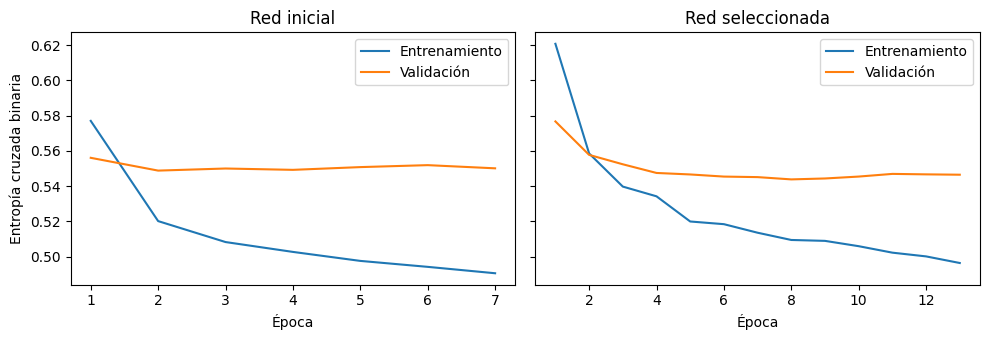

El ROC-AUC pasa de 0.7924 a 0.7994 en validación.


In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for eje, historia, titulo in zip(ejes, [historia_inicial, historia_elegida], ["Red inicial", "Red seleccionada"]):
    epocas = range(1, len(historia["loss"]) + 1)
    eje.plot(epocas, historia["loss"], label="Entrenamiento")
    eje.plot(epocas, historia["val_loss"], label="Validación")
    eje.set(xlabel="Época", title=titulo)
    eje.legend()
ejes[0].set_ylabel("Entropía cruzada binaria")
fig.tight_layout()
plt.show()
print(f"El ROC-AUC pasa de {auc_inicial:.4f} a {mejor_auc:.4f} en validación.")

### Selección del umbral

Elegimos en validación el umbral que maximiza F1 para equilibrar precisión y recall. Si varios umbrales alcanzan el mismo F1, tomamos el más alto.

In [20]:
proba_val = mejor_red(X_val, training=False).numpy().ravel()
precision, recall, umbrales = precision_recall_curve(y_val, proba_val)
suma = precision[:-1] + recall[:-1]
f1_val = np.divide(2 * precision[:-1] * recall[:-1], suma, out=np.zeros_like(suma), where=suma > 0)
indice = np.flatnonzero(f1_val == f1_val.max())[-1]
umbral = float(umbrales[indice])
print(f"Umbral seleccionado: {umbral:.4f}. F1 de validación: {f1_val[indice]:.4f}.")

Umbral seleccionado: 0.3370. F1 de validación: 0.7337.


### Evaluación en reserva

Con los pesos y el umbral fijos, hacemos una predicción por anuncio de reserva. Comparamos la red con la regla mayoritaria en los mismos alojamientos.

In [21]:
modelo = keras.Model(preprocesador.input, mejor_red(preprocesador.output), name="recomendacion")
proba_reserva = modelo.predict(dataframe_a_dataset(reserva), verbose=0).ravel()
y_reserva = etiqueta(reserva)
eval_red = medir(y_reserva, proba_reserva, umbral)
eval_mayoritaria = medir(y_reserva, np.full(len(reserva), y_train.mean()), 0.5)
display(pd.DataFrame([eval_mayoritaria, eval_red], index=["Clase mayoritaria", "Red seleccionada"]).round(4))

,auc,precision,recall,f1,exactitud
Clase mayoritaria,0.5000,0.0000,0.0000,0.0000,0.5508
Red seleccionada,0.7816,0.6023,0.8504,0.7052,0.6806


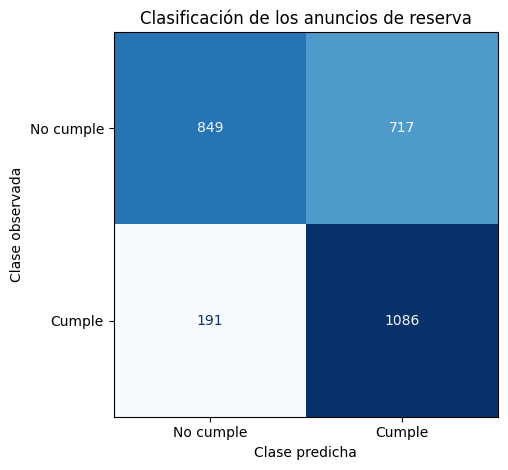

De 1,803 anuncios recomendados, 1,086 cumplen la regla y 717 no la cumplen. Otros 191 anuncios cumplen la regla y quedaron fuera de las recomendaciones.


In [22]:
matriz = confusion_matrix(y_reserva, proba_reserva >= umbral, labels=[0, 1])
vn, fp, fn, vp = map(int, matriz.ravel())
ConfusionMatrixDisplay(matriz, display_labels=["No cumple", "Cumple"]).plot(cmap="Blues", colorbar=False)
plt.xlabel("Clase predicha")
plt.ylabel("Clase observada")
plt.title("Clasificación de los anuncios de reserva")
plt.tight_layout()
plt.show()
print(f"De {vp + fp:,} anuncios recomendados, {vp:,} cumplen la regla y {fp:,} no la cumplen. "
      f"Otros {fn:,} anuncios cumplen la regla y quedaron fuera de las recomendaciones.")

### Comprobación del modelo

Juntamos la transformación de las variables con la red y comprobamos que podemos guardar el modelo y volver a cargarlo. Para la comprobación usamos un archivo temporal y una muestra de validación.

In [23]:
muestra = val.head(20)
with TemporaryDirectory() as carpeta:
    ruta_modelo = Path(carpeta) / "recomendacion.keras"
    modelo.save(ruta_modelo)
    recargado = keras.models.load_model(ruta_modelo, compile=False)
    probabilidades = recargado(entradas_modelo(muestra), training=False).numpy().ravel()
np.testing.assert_allclose(probabilidades, proba_val[:len(muestra)], atol=1e-6, rtol=1e-5)
muestra[["barrio", "tipo_habitacion"]].assign(probabilidad=probabilidades.round(3),
    recomendado=(probabilidades >= umbral).astype(int)).head()

,barrio,tipo_habitacion,probabilidad,recomendado
4,pacific beach,entire home/apt,0.819,1
10,north hills,entire home/apt,0.409,1
22,la jolla,entire home/apt,0.459,1
23,la jolla,entire home/apt,0.876,1
34,grant hill,entire home/apt,0.118,0


### Resultados de la corrida seleccionada

Registramos el umbral y las métricas de reserva en la corrida ganadora. Recuperamos esos valores desde MLflow para dejar el soporte en la salida del cuaderno.

In [24]:
with mlflow.start_run(run_id=mejor_id):
    mlflow.set_tag("seleccionado", "sí")
    mlflow.log_metrics({"umbral": umbral, "val_f1_umbral": f1_val[indice],
                        **{"reserva_" + k: v for k, v in eval_red.items()}})
ganadora = cliente.get_run(mejor_id)
print("Corrida:", ganadora.data.tags["mlflow.runName"], "· ID de MLflow:", ganadora.info.run_id)
print("Configuración:", ganadora.data.params)
display(pd.Series({k: v for k, v in ganadora.data.metrics.items()
                   if k.startswith("reserva_") or k in ["val_auc", "umbral", "val_f1_umbral"]}).round(4))

Corrida: red-23 · ID de MLflow: 83474c2d6a454f3dbe92dae2d48425ba
Configuración: {'arquitectura': '64-32', 'dropout': '0.2', 'lote': '32', 'max_epocas': '50', 'paciencia': '5', 'semilla': '100', 'tasa': '0.0003'}


reserva_auc          0.7816
reserva_exactitud    0.6806
reserva_f1           0.7052
reserva_precision    0.6023
reserva_recall       0.8504
umbral               0.3370
val_auc              0.7994
val_f1_umbral        0.7337
dtype: float64

### Interpretación

La red de dos capas obtuvo un ROC-AUC de 0,799 en validación y 0,782 en reserva. Con el umbral de 0,337 identificamos 1.086 de los 1.277 anuncios que cumplían el criterio. La precisión fue de 60,2 %: de los 1.803 anuncios que recomendaríamos, 717 quedaron por debajo de la calificación o del número de reseñas exigidos.

Este resultado nos permite identificar alojamientos para revisar. Al decidir sobre un anuncio en particular, conviene ver su historial: uno reciente puede tener buenas evaluaciones y todavía no llegar a diez reseñas.